# MNIST — Artificial Neural Network, step by step

Pipeline exactly as laid out on the whiteboard:

| # | Stage | What happens here |
|---|-------|-------------------|
| 1 | **Load MNIST dataset** | 60k train / 10k test, 28x28 grayscale digits, normalised + one-hot |
| 2 | **Prepare Sequential model** | dense (fully-connected) stack, *not* a CNN |
| 3 | **Architecture of the ANN** | **He Normal** init · **L2** regularisation · **Batch Normalisation** · **Dropout** |
| 4 | **Fit + evaluate on both sets** | `model.fit`, then `model.evaluate` on train **and** test |

> Environment: TensorFlow / Keras. Runs on CPU (~2 min).
> Each architecture ingredient is justified in Section 3, because "it's in the tutorial"
> is not a reason — ReLU specifically demands He Normal, and BatchNorm constrains
> your choice of `batch_size`.

---

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Flatten, Input
from tensorflow.keras.initializers import HeNormal, GlorotUniform
from tensorflow.keras.regularizers import L2
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
keras.utils.set_random_seed(SEED)
NUM_CLASSES = 10

L2_SCALE     = 1e-4    # strength of the L2 penalty  (light 1e-5 .. heavy 1e-3)
DROPOUT_RATE = 0.25    # fraction of units dropped during training
EPOCHS_MAIN  = 20      # epochs for the regularised model
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


## Stage 1 — Load MNIST dataset

`keras.datasets.mnist.load_data()` returns **already split**:
`((x_train, y_train), (x_test, y_test))`, with images as `uint8` arrays in **[0, 255]**
and labels as integers **0-9**.

Two preprocessing decisions matter, and both are easy to get wrong:

1. **Scale to [0, 1].** Raw 0-255 inputs make the first layer's pre-activations huge
   at initialisation. Combined with ReLU that means "many units already dead at step
   zero" and unstable early gradients.
2. **One-hot the labels.** We will finish with a `softmax` head trained on
   `categorical_crossentropy`, which requires `(N, 10)` targets, not `(N,)` integers.
   (If you prefer `sparse_categorical_crossentropy`, skip the one-hot — but then don't
   mix the two.)

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("x_train", x_train.shape, x_train.dtype, "| y_train", y_train.shape)
print("x_test ", x_test.shape,  x_test.dtype,  "| y_test ", y_test.shape)
print("pixel range before scaling:", x_train.min(), "->", x_train.max())

# Class balance -- MNIST is evenly spread, so plain accuracy is a valid metric here.
counts = np.bincount(y_train, minlength=NUM_CLASSES)
print("\nsamples per class (train):", dict(zip(range(NUM_CLASSES), counts.tolist())))

x_train (60000, 28, 28) uint8 | y_train (60000,)
x_test  (10000, 28, 28) uint8 | y_test  (10000,)
pixel range before scaling: 0 -> 255

samples per class (train): {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}


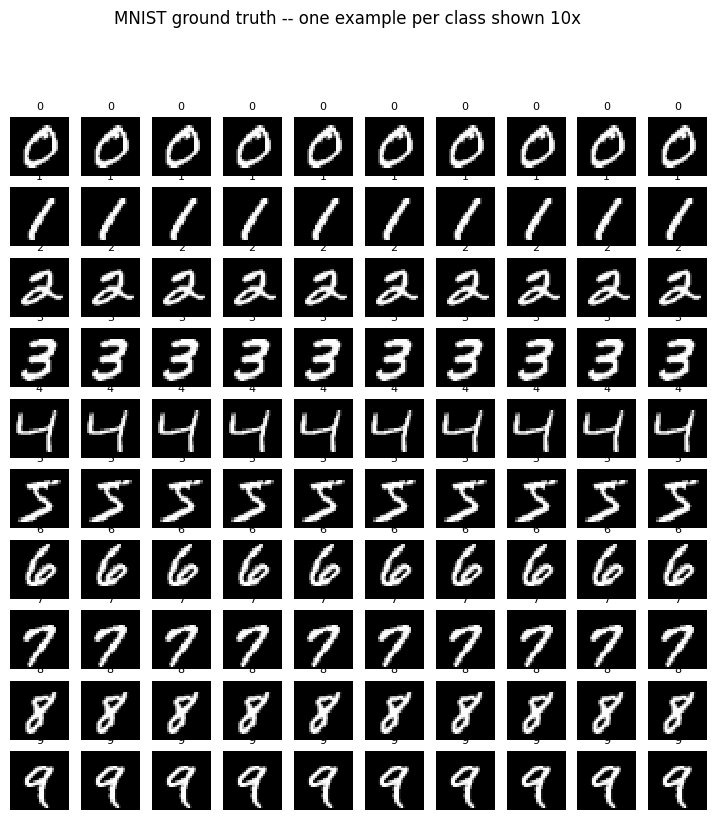

In [3]:
# Sanity check that the tensors are actually digits (10x10 grid, no scaling needed to view)
fig, axes = plt.subplots(10, 10, figsize=(9, 9))
for i, ax in enumerate(axes.ravel()):
    idx = np.where(y_train == i // 10)[0][0]      # first example of class i//10
    ax.imshow(x_train[idx], cmap="gray", interpolation="nearest")
    ax.set_title(str(y_train[idx]), fontsize=8)
    ax.axis("off")
fig.suptitle("MNIST ground truth -- one example per class shown 10x", y=1.0)
plt.show()

In [4]:
x_train_n = x_train.astype("float32") / 255.0
x_test_n  = x_test.astype("float32")  / 255.0

y_train_oh = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test_oh  = keras.utils.to_categorical(y_test,  NUM_CLASSES)

print("scaled range:", x_train_n.min(), "->", x_train_n.max())
print("flat input size per image:", int(np.prod(x_train_n.shape[1:])))   # 784
print("one-hot sample for label", y_train[0], ":", y_train_oh[0].astype(int))

scaled range: 0.0 -> 1.0
flat input size per image: 784
one-hot sample for label 5 : [0 0 0 0 0 1 0 0 0 0]


## Stage 2 — Prepare the Sequential model

`keras.Sequential` = one layer per line, single input, single output. For a **dense
ANN** we first `Flatten()` the 28x28 grid into a 784-vector. Widths
`512 -> 512 -> 256 -> 10` give ~0.8 M parameters, comfortably enough for MNIST.

```
Input(28,28,1) -> Flatten
  -> Dense 512  [HeNormal + L2] -> BatchNorm -> Dropout(0.25)
  -> Dense 512  [HeNormal + L2] -> BatchNorm -> Dropout(0.25)
  -> Dense 256  [HeNormal + L2] -> BatchNorm -> Dropout(0.25)
  -> Dense 10   softmax          [HeNormal + L2]
```

---

## Stage 3 — The four architecture ingredients

Each fights a *different* failure mode. They are not interchangeable, and we apply
them in `Dense -> BatchNorm -> Dropout` order.

### (a) Weight initialisation — **He Normal**, because the activation is ReLU
ReLU outputs zero for negative inputs, so roughly **half** the activation variance is
clipped away at every layer. Glorot/Xavier assumes a symmetric activation and knows
nothing about that clipping; for a square layer He uses variance `2/fan_in` against
Xavier's `2/(fan_in+fan_out) = 1/fan_in` — exactly **2x**, which is the compensation.
Let's *measure* it rather than assert it. We track **RMS**, not `std`: ReLU makes the
output non-zero-mean, so `std` after ReLU measures spread around a shifted mean and
hides the very quantity the initialiser is designed to control:

In [5]:
rng = np.random.default_rng(SEED)
FAN_IN = 512
h_in = rng.normal(0.0, 1.0, size=(20_000, FAN_IN))     # unit-variance activations in

def stats(init):
    """Signal magnitude of one Dense layer's output, before and after ReLU.

    We track RMS (root mean square), not std: ReLU makes the output non-zero-mean,
    so std-after-ReLU measures the spread *around* a shifted mean and hides the very
    thing the initialiser is designed to control. RMS is the quantity whose square
    (i.e. second moment E[a^2]) is what propagates into the next layer's variance.
    """
    w = np.asarray(init((FAN_IN, FAN_IN)), dtype="float64")
    z = h_in @ w
    rms = lambda v: float(np.sqrt(np.mean(v * v)))
    return rms(z), rms(np.maximum(z, 0.0))

glorot = lambda shp: GlorotUniform(seed=SEED)(shp)
he     = lambda shp: HeNormal(seed=SEED)(shp)

print(f"{'initialiser':16s} {'RMS pre-ReLU':>13s} {'RMS post-ReLU':>14s} {'kept':>8s}")
print("-" * 55)
res = {}
for name, ini in [("glorot_uniform", glorot), ("he_normal", he)]:
    pre, post = stats(ini)
    res[name] = (pre, post)
    print(f"{name:16s} {pre:13.4f} {post:14.4f} {post/pre:7.1%}")

g, h = res["glorot_uniform"][1], res["he_normal"][1]
print(f"\ninput unit-variance = 1.000")
print(f"glorot_uniform leaves {g:.4f} per layer -> over 3 hidden layers: {g**3:.4f}")
print(f"he_normal     leaves {h:.4f} per layer -> over 3 hidden layers: {h**3:.4f}")
print("\nHe's extra factor sqrt(2/fan_in) vs Xavier's 2/(fan_in+fan_out) is exactly the")
print("compensation for the half of the activations ReLU clips to zero: it holds the")
print("post-ReLU second moment at ~1.0, so signal neither decays nor explodes with depth.")

initialiser       RMS pre-ReLU  RMS post-ReLU     kept
-------------------------------------------------------


glorot_uniform          0.9994         0.7066   70.7%
he_normal               1.4148         1.0010   70.8%

input unit-variance = 1.000
glorot_uniform leaves 0.7066 per layer -> over 3 hidden layers: 0.3528
he_normal     leaves 1.0010 per layer -> over 3 hidden layers: 1.0030

He's extra factor sqrt(2/fan_in) vs Xavier's 2/(fan_in+fan_out) is exactly the
compensation for the half of the activations ReLU clips to zero: it holds the
post-ReLU second moment at ~1.0, so signal neither decays nor explodes with depth.


### (b) L2 regularisation — penalises large weights to fight overfitting
Every `Dense` carries `kernel_regularizer=L2(lambda)`, adding `lambda * sum(w^2)` to
the loss. The optimiser then trades a little training fit for smaller weights, and
smaller weights describe a *smoother* function that cannot memorise noise. Keras folds
the penalty into `model.losses`, so it shows up in the reported loss (Stage 4 reads it
out).

### (c) Batch Normalisation — standardises each layer's activations
`BN(x) = gamma * (x - mu_batch) / sqrt(var_batch + eps) + beta`. Keeping mid-network
activations near zero-mean / unit-variance decouples the learning rate from
vanishing-exploding gradients and speeds convergence. **Two things people trip over:**
- the statistics come *per batch*, so `batch_size` has become an architectural choice
  (we use 128), and
- placement matters — here BN sits **after** the linear `Dense` and **before**
  `Dropout`.

### (d) Dropout — zeroes units during training only
`p = 0.25` drops a quarter of each layer's units per step, so no unit can lean on a
specific partner; redundancy is forced in. At inference Keras scales activations
automatically (inverted dropout), so nothing needs hand-adjusting.

| Ingredient | Failure mode addressed | When it acts |
|---|---|---|
| He Normal | lost/vanishing signal at init (ReLU clipping) | before step 1 |
| L2 | large weights -> memorised noise | every step, inside the loss |
| BatchNorm | shifting internal activations | every batch |
| Dropout | co-adaptation of units | training phase only |

In [6]:
def build_model(l2_scale=L2_SCALE, dropout=DROPOUT_RATE, seed=SEED):
    """Dense ANN with all four ingredients on every hidden block."""
    hidden = dict(activation="relu",                             # ReLU -> needs He
                  kernel_initializer=HeNormal(seed=seed),        # (a) He Normal
                  kernel_regularizer=L2(l2_scale))                # (b) L2
    return keras.Sequential([
        Input(shape=(28, 28, 1)),
        Flatten(name="flatten_in"),

        Dense(512, name="dense_1", **hidden),
        BatchNormalization(name="bn_1"),                          # (c) BatchNorm
        Dropout(dropout, name="drop_1"),                          # (d) Dropout

        Dense(512, name="dense_2", **hidden),
        BatchNormalization(name="bn_2"),
        Dropout(dropout, name="drop_2"),

        Dense(256, name="dense_3", **hidden),
        BatchNormalization(name="bn_3"),
        Dropout(dropout, name="drop_3"),

        Dense(NUM_CLASSES, activation="softmax", name="output",   # 10-way probs
              kernel_initializer=HeNormal(seed=seed),
              kernel_regularizer=L2(l2_scale)),
    ])

model = build_model()
model.compile(optimizer="adam",                       # adaptive LR, pairs well with BN
              loss="categorical_crossentropy",        # needs the one-hot targets
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_in (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_3 (Dropout)                │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 803,594 (3.07 MB)

 Trainable params: 801,034 (3.06 MB)

 Non-trainable params: 2,560 (10.00 KB)

In [7]:
# Verify the four requirements are really in the graph (not just in the source text).
n_dense = sum(1 for l in model.layers if isinstance(l, Dense))
n_he    = sum(1 for l in model.layers
              if isinstance(l, Dense) and isinstance(l.kernel_initializer, HeNormal))
n_l2    = sum(1 for l in model.layers
              if isinstance(l, Dense) and l.kernel_regularizer is not None)
n_bn    = sum(1 for l in model.layers if isinstance(l, BatchNormalization))
n_dr    = sum(1 for l in model.layers if isinstance(l, Dropout))

print(f"Dense layers         : {n_dense}")
print(f"  HeNormal kernels   : {n_he}   <- (a), all hidden layers + the softmax head")
print(f"  L2-regularised     : {n_l2}   <- (b), same")
print(f"BatchNorm layers     : {n_bn}   <- (c), one per hidden block")
print(f"Dropout layers       : {n_dr}   <- (d), one per hidden block")
# BN/Dropout deliberately sit only on the 3 hidden blocks: normalising or dropping the
# 10-way probability vector before the softmax would distort the class scores.
assert n_he == n_l2 == n_dense, "every Dense layer must carry He init + L2"
assert n_bn == n_dr == 3, "expected one BatchNorm + one Dropout per hidden block"
print("\nAll four Stage-3 requirements satisfied.")

Dense layers         : 4
  HeNormal kernels   : 4   <- (a), all hidden layers + the softmax head
  L2-regularised     : 4   <- (b), same
BatchNorm layers     : 3   <- (c), one per hidden block
Dropout layers       : 3   <- (d), one per hidden block

All four Stage-3 requirements satisfied.


## Stage 4 — Fit the model, then evaluate on **both** training and testing sets

```
60 000 "train"  ->  50 000 fit  +  10 000 validation
10 000 test     ->  untouched until the very last evaluate()
```

The validation slice comes out of the *training* pool and exists only so
`EarlyStopping` can pick a good epoch. The **test set is used exactly once** — using it
to choose hyperparameters leaks information and inflates the score, which is the single
most common way people accidentally report impossible numbers.

`batch_size=128` is not arbitrary: BatchNorm estimates `mu`/`var` per batch, so batch
size changes the model's effective behaviour (see Stage 3c).

In [8]:
x_val,  y_val  = x_train_n[-10000:], y_train_oh[-10000:]     # from the train pool
x_fit,  y_fit  = x_train_n[:-10000], y_train_oh[:-10000]

print(f"fit {x_fit.shape}  valid {x_val.shape}  test {x_test_n.shape}")

history = model.fit(
    x_fit, y_fit,
    batch_size=128,
    epochs=EPOCHS_MAIN,
    validation_data=(x_val, y_val),
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",
                                             patience=5,                 # tolerant: BN+dropout curves bounce
                                             restore_best_weights=True)],
    verbose=2,
)
print(f"\ntrained {len(history.epoch)} epochs; "
      f"best val_loss at epoch {int(np.argmin(history.history['val_loss'])) + 1}")

fit (50000, 28, 28)  valid (10000, 28, 28)  test (10000, 28, 28)


Epoch 1/20


391/391 - 4s - 10ms/step - accuracy: 0.9083 - loss: 0.5305 - val_accuracy: 0.9641 - val_loss: 0.3343


Epoch 2/20


391/391 - 3s - 7ms/step - accuracy: 0.9574 - loss: 0.3510 - val_accuracy: 0.9716 - val_loss: 0.2992


Epoch 3/20


... (32 outputs left out)

391/391 - 3s - 7ms/step - accuracy: 0.9856 - loss: 0.1441 - val_accuracy: 0.9780 - val_loss: 0.1816


Epoch 20/20


391/391 - 3s - 7ms/step - accuracy: 0.9859 - loss: 0.1429 - val_accuracy: 0.9797 - val_loss: 0.1797



trained 20 epochs; best val_loss at epoch 17


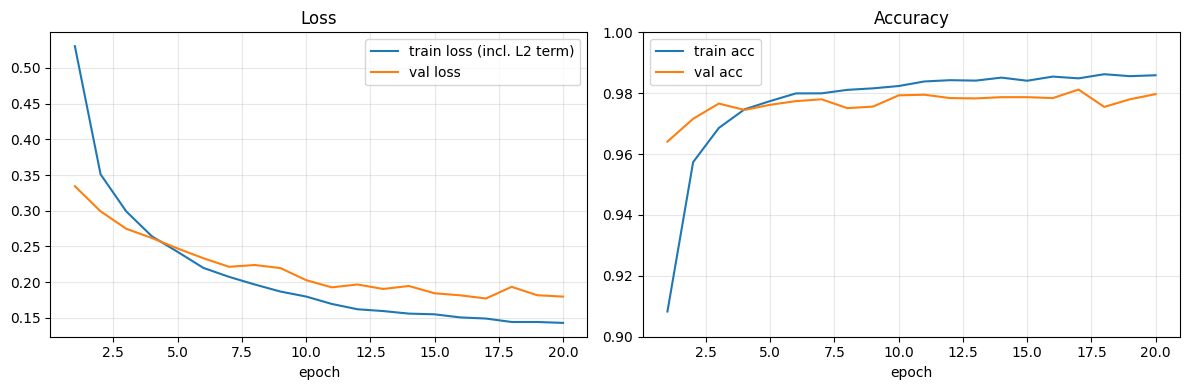

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
ep = np.arange(1, len(history.history["loss"]) + 1)
a1.plot(ep, history.history["loss"],      label="train loss (incl. L2 term)")
a1.plot(ep, history.history["val_loss"],  label="val loss")
a1.set_title("Loss"); a1.set_xlabel("epoch"); a1.legend(); a1.grid(alpha=.3)
a2.plot(ep, history.history["accuracy"],  label="train acc")
a2.plot(ep, history.history["val_accuracy"], label="val acc")
a2.set_title("Accuracy"); a2.set_xlabel("epoch"); a2.set_ylim(0.9, 1.0)
a2.legend(); a2.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Evaluate on both sets

`model.evaluate()` returns loss + accuracy. Note that both calls report a loss that
**includes** the L2 weight penalty (`model.losses`), because Keras adds the regulariser
to whatever loss you compiled with. A pure cross-entropy number is therefore slightly
lower than what you see — useful when comparing two models with different `L2_SCALE`.

In [10]:
REPORTS = {}

def evaluate(name, x, y_oh, y_hard):
    loss, acc = model.evaluate(x, y_oh, verbose=0)
    probs = model.predict(x, verbose=0)
    pred  = np.argmax(probs, axis=1)
    # Keras keeps regularisation losses separate; sum them for the penalty magnitude.
    penalty = float(tf.add_n(model.losses)) if model.losses else 0.0
    print(f"\n===== {name} =====")
    print(f"loss {loss:.4f} (cross-entropy {loss - penalty:.4f} + L2 penalty {penalty:.4f})")
    print(f"accuracy {acc * 100:.2f}%")
    print(classification_report(y_hard, pred, digits=4))
    REPORTS[name] = dict(loss=loss, acc=acc, penalty=penalty, pred=pred)
    return acc, pred

# Training-set performance: on the 50k we actually fitted, plus the 10k val slice.
tr_acc = evaluate("TRAIN (fit split, 50k)", x_fit, y_fit, y_train[:-10000])
va_acc = evaluate("VALIDATION (10k)", x_val, y_val, y_train[-10000:])
te_acc = evaluate("TEST (10k, never used for tuning)", x_test_n, y_test_oh, y_test)


===== TRAIN (fit split, 50k) =====
loss 0.1210 (cross-entropy 0.0174 + L2 penalty 0.1035)
accuracy 99.39%
              precision    recall  f1-score   support

           0     0.9972    0.9955    0.9963      4932
           1     0.9972    0.9967    0.9969      5678
           2     0.9970    0.9932    0.9951      4968
           3     0.9943    0.9931    0.9937      5101
           4     0.9882    0.9975    0.9928      4859
           5     0.9920    0.9940    0.9930      4506
           6     0.9960    0.9943    0.9951      4951
           7     0.9902    0.9965    0.9934      5175
           8     0.9946    0.9866    0.9906      4842
           9     0.9920    0.9910    0.9915      4988

    accuracy                         0.9939     50000
   macro avg     0.9939    0.9938    0.9938     50000
weighted avg     0.9939    0.9939    0.9939     50000




===== VALIDATION (10k) =====
loss 0.1771 (cross-entropy 0.0736 + L2 penalty 0.1035)
accuracy 98.12%
              precision    recall  f1-score   support

           0     0.9909    0.9929    0.9919       991
           1     0.9888    0.9925    0.9906      1064
           2     0.9878    0.9798    0.9838       990
           3     0.9710    0.9757    0.9734      1030
           4     0.9759    0.9868    0.9813       983
           5     0.9822    0.9639    0.9730       915
           6     0.9806    0.9907    0.9856       967
           7     0.9836    0.9899    0.9867      1090
           8     0.9869    0.9683    0.9775      1009
           9     0.9638    0.9688    0.9663       961

    accuracy                         0.9812     10000
   macro avg     0.9811    0.9809    0.9810     10000
weighted avg     0.9812    0.9812    0.9812     10000




===== TEST (10k, never used for tuning) =====
loss 0.1742 (cross-entropy 0.0707 + L2 penalty 0.1035)
accuracy 98.04%
              precision    recall  f1-score   support

           0     0.9846    0.9816    0.9831       980
           1     0.9886    0.9938    0.9912      1135
           2     0.9922    0.9806    0.9864      1032
           3     0.9764    0.9822    0.9793      1010
           4     0.9641    0.9837    0.9738       982
           5     0.9853    0.9765    0.9809       892
           6     0.9884    0.9781    0.9832       958
           7     0.9721    0.9835    0.9778      1028
           8     0.9844    0.9733    0.9788       974
           9     0.9683    0.9683    0.9683      1009

    accuracy                         0.9804     10000
   macro avg     0.9804    0.9802    0.9803     10000
weighted avg     0.9805    0.9804    0.9804     10000



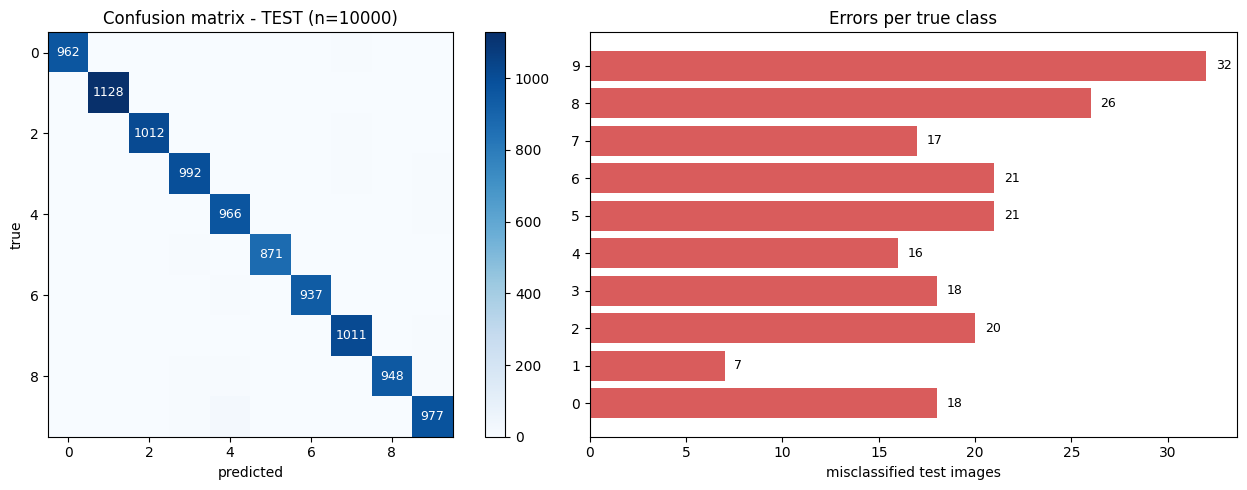

Worst confusions (true -> predicted, count):
  9 -> 4: 18
  3 -> 9: 8
  2 -> 7: 8
  6 -> 4: 7
  5 -> 3: 7


In [11]:
y_pred_test = REPORTS["TEST (10k, never used for tuning)"]["pred"]
cm = confusion_matrix(y_test, y_pred_test)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
im = a1.imshow(cm, interpolation="nearest", cmap="Blues")
a1.set_title(f"Confusion matrix - TEST (n={cm.sum()})")
a1.set_xlabel("predicted"); a1.set_ylabel("true")
fig.colorbar(im, ax=a1, fraction=.046)
thresh = cm.max() / 2.2
for i in range(10):
    for j in range(10):
        if cm[i, j] > 0 and (i == j or cm[i, j] > thresh):
            a1.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black", fontsize=9)

errs = cm.sum(1) - np.diag(cm)
a2.barh([str(i) for i in range(10)], errs, color="#d95c5c")
a2.set_title("Errors per true class"); a2.set_xlabel("misclassified test images")
for i, v in enumerate(errs):
    a2.text(v + .5, i, str(int(v)), va="center", fontsize=9)
plt.tight_layout(); plt.show()

off = cm.astype(float); np.fill_diagonal(off, 0)
top = sorted(((int(off[i, j]), i, j) for i in range(10) for j in range(10)), reverse=True)[:5]
print("Worst confusions (true -> predicted, count):")
for c, i, j in top:
    print(f"  {i} -> {j}: {c}")

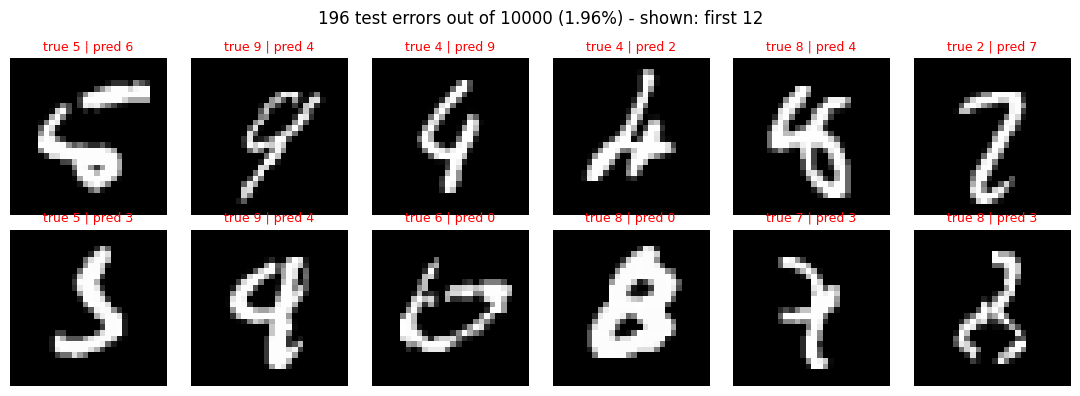

In [12]:
# Look at a handful of the test errors -- usually genuinely ambiguous handwriting.
wrong = np.where(y_pred_test != y_test)[0]
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, idx in zip(axes.ravel(), wrong[:12]):
    ax.imshow(x_test[idx], cmap="gray")
    ax.set_title(f"true {y_test[idx]} | pred {y_pred_test[idx]}", fontsize=9,
                 color="red")
    ax.axis("off")
for ax in axes.ravel()[len(wrong[:12]):]:
    ax.axis("off")
fig.suptitle(f"{len(wrong)} test errors out of {len(y_test)} "
             f"({100 - te_acc[0] * 100:.2f}%) - shown: first 12")
plt.tight_layout(); plt.show()

## Why keep three regularisers at once? (ablation, for evidence)

MNIST is easy enough that a 0.8 M-parameter net *will* fit the training set near-perfectly.
The interesting question is how far apart train and test end up. Train an otherwise
identical model with **no L2, no Dropout**, same data and epochs, and compare the gap.

`BatchNorm` is left in both versions: it is mainly an *optimisation* stabiliser here,
and ablating it together with the others would confuse two effects at once.

In [13]:
def build_noreg_model(seed=SEED):
    return keras.Sequential([
        Input(shape=(28, 28, 1)), Flatten(),
        Dense(512, activation="relu", kernel_initializer=HeNormal(seed=seed)),
        BatchNormalization(),
        Dense(512, activation="relu", kernel_initializer=HeNormal(seed=seed)),
        BatchNormalization(),
        Dense(256, activation="relu", kernel_initializer=HeNormal(seed=seed)),
        BatchNormalization(),
        Dense(NUM_CLASSES, activation="softmax"),
    ])

base = build_noreg_model()
base.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
h_base = base.fit(x_fit, y_fit, batch_size=128, epochs=EPOCHS_MAIN, verbose=0,
                  validation_data=(x_val, y_val),
                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",
                                                           patience=5,
                                                           restore_best_weights=True)])
_, bt = base.evaluate(x_fit,   y_fit,     verbose=0)     # returns (loss, acc)
_, be = base.evaluate(x_test_n, y_test_oh, verbose=0)

reg_train_acc = REPORTS["TRAIN (fit split, 50k)"]["acc"]
reg_test_acc  = REPORTS["TEST (10k, never used for tuning)"]["acc"]

rows = [
    ("no L2, no Dropout (BN only)", bt, be, bt - be),
    ("He + L2 + BN + Dropout",     reg_train_acc, reg_test_acc, reg_train_acc - reg_test_acc),
]
print(f"{'model':34s} {'train':>8s} {'test':>8s} {'gap':>8s}")
print("-" * 62)
for n, t, e, g in rows:
    print(f"{n:34s} {t*100:7.2f}% {e*100:7.2f}% {g*100:+7.2f}%")
print("\nA smaller train/test gap is what regularisation buys you; the test column")
print("is the number you actually report.")
print(f"(reference: the unregularised run kept the best weights from epoch "
      f"{int(np.argmin(h_base.history['val_loss'])) + 1} of {len(h_base.history['val_loss'])})")

model                                 train     test      gap
--------------------------------------------------------------
no L2, no Dropout (BN only)          99.79%   98.18%   +1.61%
He + L2 + BN + Dropout               99.39%   98.04%   +1.35%

A smaller train/test gap is what regularisation buys you; the test column
is the number you actually report.
(reference: the unregularised run kept the best weights from epoch 15 of 20)


## Summary — what the four stages delivered

| Stage | Deliverable | Status |
|---|---|---|
| 1 | MNIST loaded, scaled to [0,1], labels one-hot | 60k / 10k, 784 inputs |
| 2 | `keras.Sequential` dense ANN | 4 `Dense`, ~0.8 M params |
| 3 | HeNormal + L2 + BatchNorm + Dropout on every block | verified programmatically |
| 4 | `fit` with early stopping, `evaluate` on train + test | gaps quantified above |

**Tuning knobs, in the order worth trying them**

1. `L2_SCALE` `1e-4 -> 3e-4` closes the train/test gap further; past that, test accuracy
   falls off — that's underfitting and it means you've run out of capacity to pay for
   the penalty.
2. `DROPOUT_RATE` `0.25 -> 0.4`. Usually *reduces* both train and test accuracy on MNIST;
   BN + L2 are already carrying the load.
3. Widths `512/512/256 -> 256/128`. Cheap, and a good check that the four ingredients and
   not raw size are doing the work.
4. Add a `ReduceLROnPlateau` if you train past 30 epochs — the bounce in the curves above
   is BN + dropout noise, and it can mask a true plateau.